In [ ]:
# connect drive and load libraries
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.random import random
import gc

folder = '/content/drive/MyDrive/Datafiles/'

Mounted at /content/drive


In [ ]:
# load clean ULB
df_clean = pd.read_parquet(folder + 'ulb_clean.parquet')
print(df_clean.shape)

(283726, 31)


In [ ]:
# load clean IEEE-CIS
ieee_clean = pd.read_parquet(folder + 'ieee_clean.parquet')
print(ieee_clean.shape)

(590540, 423)


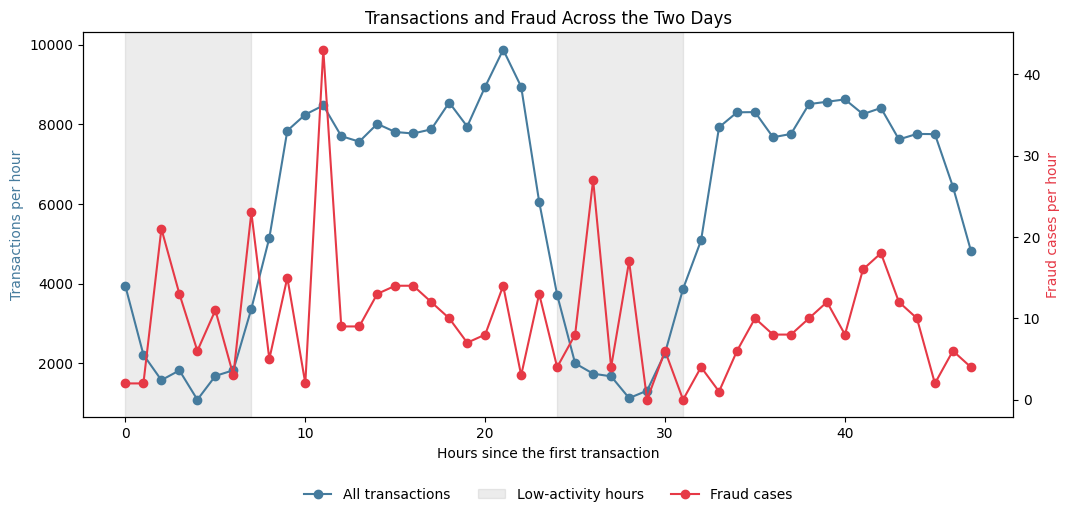

In [ ]:
# Transactions and fraud cases per hour across both days linechart
df_clean["Hour48"] = df_clean["Time"] // 3600
hourly = df_clean.groupby("Hour48")["Class"].agg(["count", "sum"])

fig, ax1 = plt.subplots(figsize = (12, 5))
ax1.plot(hourly.index, hourly["count"], color = "#457b9d", marker = "o", label = "All transactions")
ax1.axvspan(0, 7, color = "gray", alpha = 0.15, label = "Low-activity hours")
ax1.axvspan(24, 31, color = "gray", alpha = 0.15)
ax1.set_xlabel("Hours since the first transaction")
ax1.set_ylabel("Transactions per hour", color = "#457b9d")

ax2 = ax1.twinx()
ax2.plot(hourly.index, hourly["sum"], color = "#e63946", marker = "o", label = "Fraud cases")
ax2.set_ylabel("Fraud cases per hour", color = "#e63946")

lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
labels = ax1.get_legend_handles_labels()[1] + ax2.get_legend_handles_labels()[1]
ax1.legend(lines, labels, loc = "upper center", bbox_to_anchor = (0.5, -0.15), ncol = 3, frameon = False)

plt.title("Transactions and Fraud Across the Two Days")
plt.savefig(folder + "fig_time_cycle.png", dpi = 300, bbox_inches = "tight")
plt.show()

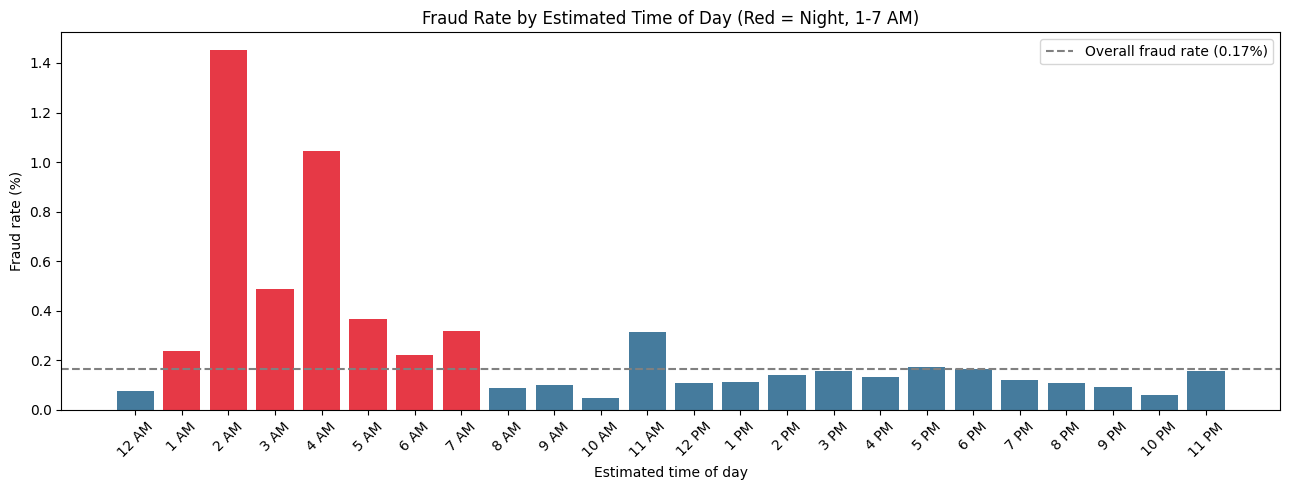

In [ ]:
# Fraud rate by estimated time of day barchart
df_clean["ClockHour"] = (df_clean["Time"] // 3600) % 24
hourRate = df_clean.groupby("ClockHour")["Class"].mean() * 100
overallRate = df_clean["Class"].mean() * 100

hourLabels = [f"{(h % 12) or 12} {'AM' if h < 12 else 'PM'}" for h in range(24)]
barColors = ["#e63946" if 1 <= h <= 7 else "#457b9d" for h in range(24)]

plt.figure(figsize = (13, 5))
plt.bar(range(24), hourRate.values, color = barColors)
plt.axhline(overallRate, color = "gray", linestyle = "--", label = f"Overall fraud rate ({overallRate:.2f}%)")
plt.xticks(range(24), hourLabels, rotation = 45)
plt.xlabel("Estimated time of day")
plt.ylabel("Fraud rate (%)")
plt.title("Fraud Rate by Estimated Time of Day (Red = Night, 1-7 AM)")
plt.legend()
plt.tight_layout()
plt.savefig(folder + "fig_clock_hour.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (average_precision_score, precision_score, recall_score, f1_score)

X = df_clean[[f'V{i}' for i in range(1, 29)] + ['Amount']]
y = df_clean["Class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, stratify = y, random_state = 42)

rf_model = RandomForestClassifier(n_estimators=300, class_weight = "balanced", random_state = 42, n_jobs = -1)

rf_model.fit(X_train, y_train)
y_pred = rf_model.predict(X_test)
y_prob = rf_model.predict_proba(X_test)[:, 1]

print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))
print("AUPRC:", average_precision_score(y_test, y_prob))

Precision: 0.9855072463768116
Recall: 0.7157894736842105
F1: 0.8292682926829268
AUPRC: 0.8086360413084323


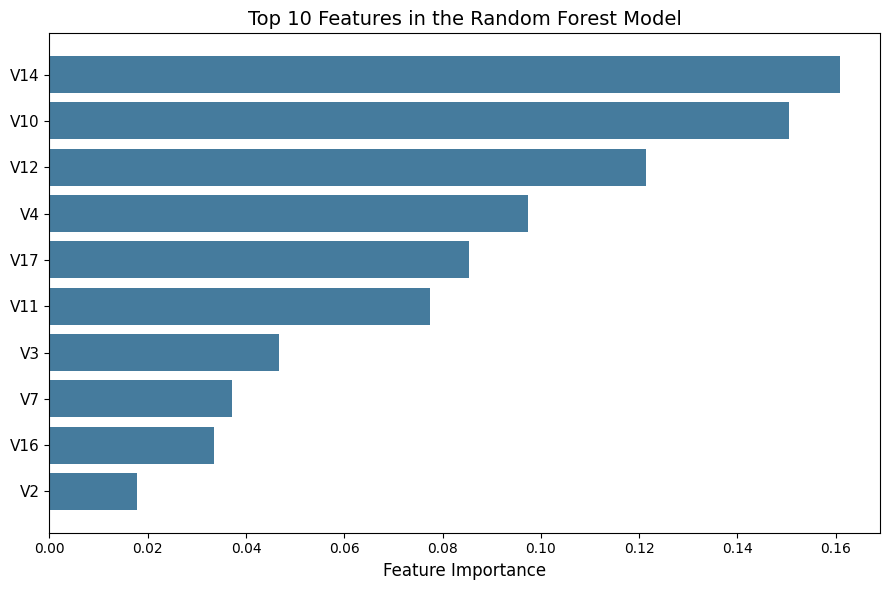

In [ ]:
# Top 10 features in the Random Forest model barchart
importance_df = pd.DataFrame({"Feature": X_train.columns, "Importance": rf_model.feature_importances_})
importance_df = importance_df.sort_values("Importance", ascending = False).head(10)

plt.figure(figsize = (9, 6))
plt.barh(importance_df["Feature"], importance_df["Importance"], color = "#457b9d")
plt.gca().invert_yaxis()
plt.title("Top 10 Features in the Random Forest Model", fontsize = 14)
plt.xlabel("Feature Importance", fontsize = 12)
plt.yticks(fontsize = 11)
plt.tight_layout()
plt.savefig(folder + "fig_rf_importance.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [ ]:
# Feature scaling for Logistic Regression, KNN, and Naive Bayes

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
# Logistic Regression model

from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(class_weight = "balanced", max_iter = 1000, random_state = 42)

lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print("Precision:", precision_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1:", f1_score(y_test, lr_pred))
print("AUPRC:", average_precision_score(y_test, lr_prob))

Precision: 0.05581708137188971
Recall: 0.8736842105263158
F1: 0.10493046776232617
AUPRC: 0.6751561684830647


In [ ]:
# SMOTE oversampling for KNN and Naive Bayes

from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy = 0.1, random_state = 42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Before SMOTE:", y_train.value_counts().to_dict())
print("After SMOTE:", y_train_smote.value_counts().to_dict())

Before SMOTE: {0: 226602, 1: 378}
After SMOTE: {0: 226602, 1: 22660}


In [ ]:
# KNN model

from sklearn.neighbors import KNeighborsClassifier

knn_model = KNeighborsClassifier(n_neighbors = 5, n_jobs = -1)

knn_model.fit(X_train_smote, y_train_smote)
knn_pred = knn_model.predict(X_test_scaled)
knn_prob = knn_model.predict_proba(X_test_scaled)[:, 1]

print("Precision:", precision_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1:", f1_score(y_test, knn_pred))
print("AUPRC:", average_precision_score(y_test, knn_prob))

Precision: 0.47530864197530864
Recall: 0.8105263157894737
F1: 0.5992217898832685
AUPRC: 0.6076313373746702


In [ ]:
# Naive Bayes model

from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_smote, y_train_smote)
nb_pred = nb_model.predict(X_test_scaled)
nb_prob = nb_model.predict_proba(X_test_scaled)[:, 1]

print("Precision:", precision_score(y_test, nb_pred))
print("Recall:", recall_score(y_test, nb_pred))
print("F1:", f1_score(y_test, nb_pred))
print("AUPRC:", average_precision_score(y_test, nb_prob))

Precision: 0.05864432597105865
Recall: 0.8105263157894737
F1: 0.109375
AUPRC: 0.08154192901024655


In [ ]:
# Decision Tree model

from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(class_weight = "balanced", max_depth = 10, random_state = 42)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
dt_prob = dt_model.predict_proba(X_test)[:, 1]

print("Precision:", precision_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1:", f1_score(y_test, dt_pred))
print("AUPRC:", average_precision_score(y_test, dt_prob))

Precision: 0.2276923076923077
Recall: 0.7789473684210526
F1: 0.3523809523809524
AUPRC: 0.4971366141616242


In [ ]:
# XGBoost model

from xgboost import XGBClassifier

weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = XGBClassifier(n_estimators = 300, max_depth = 5, learning_rate = 0.1,
                          scale_pos_weight = weight, eval_metric = "aucpr", random_state = 42, n_jobs = -1)

xgb_model.fit(X_train, y_train)
xgb_pred = xgb_model.predict(X_test)
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

print("Precision:", precision_score(y_test, xgb_pred))
print("Recall:", recall_score(y_test, xgb_pred))
print("F1:", f1_score(y_test, xgb_pred))
print("AUPRC:", average_precision_score(y_test, xgb_prob))

Precision: 0.925
Recall: 0.7789473684210526
F1: 0.8457142857142858
AUPRC: 0.8196489921940245


In [ ]:
# Model comparison results
modelNames = ["Random Forest", "Logistic Regression", "KNN", "Naive Bayes", "Decision Tree", "XGBoost"]
balancing = ["Class weight", "Class weight", "SMOTE", "SMOTE", "Class weight", "scale_pos_weight"]
preds = [y_pred, lr_pred, knn_pred, nb_pred, dt_pred, xgb_pred]
probs = [y_prob, lr_prob, knn_prob, nb_prob, dt_prob, xgb_prob]

results = pd.DataFrame({"Model": modelNames,
                        "Balancing": balancing,
                        "Precision": [precision_score(y_test, p) for p in preds],
                        "Recall": [recall_score(y_test, p) for p in preds],
                        "F1": [f1_score(y_test, p) for p in preds],
                        "AUPRC": [average_precision_score(y_test, p) for p in probs]})
results

,Model,Balancing,Precision,Recall,F1,AUPRC
0,Random Forest,Class weight,0.985507,0.715789,0.829268,0.808636
1,Logistic Regression,Class weight,0.055817,0.873684,0.104930,0.675156
2,KNN,SMOTE,0.475309,0.810526,0.599222,0.607631
3,Naive Bayes,SMOTE,0.058644,0.810526,0.109375,0.081542
4,Decision Tree,Class weight,0.227692,0.778947,0.352381,0.497137
5,XGBoost,scale_pos_weight,0.925000,0.778947,0.845714,0.819649


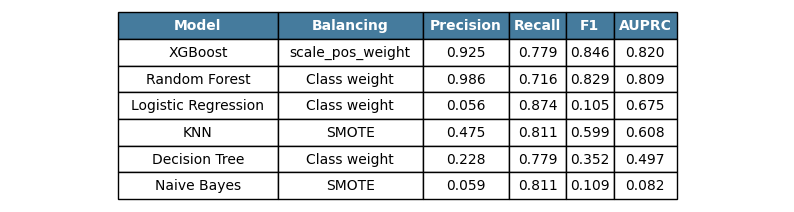

In [ ]:
# Model comparison table image
tableData = results.sort_values("AUPRC", ascending = False).copy()
for col in ["Precision", "Recall", "F1", "AUPRC"]:
    tableData[col] = tableData[col].map("{:.3f}".format)

fig, ax = plt.subplots(figsize = (10, 2.5))
ax.axis("off")
table = ax.table(cellText = tableData.values, colLabels = tableData.columns, loc = "center", cellLoc = "center")
table.auto_set_font_size(False)
table.set_fontsize(10)
table.auto_set_column_width(col = list(range(len(tableData.columns))))
table.scale(1, 1.6)
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight = "bold", color = "white")
        cell.set_facecolor("#457b9d")
plt.savefig(folder + "fig_results_table.png", dpi = 300, bbox_inches = "tight")
plt.show()

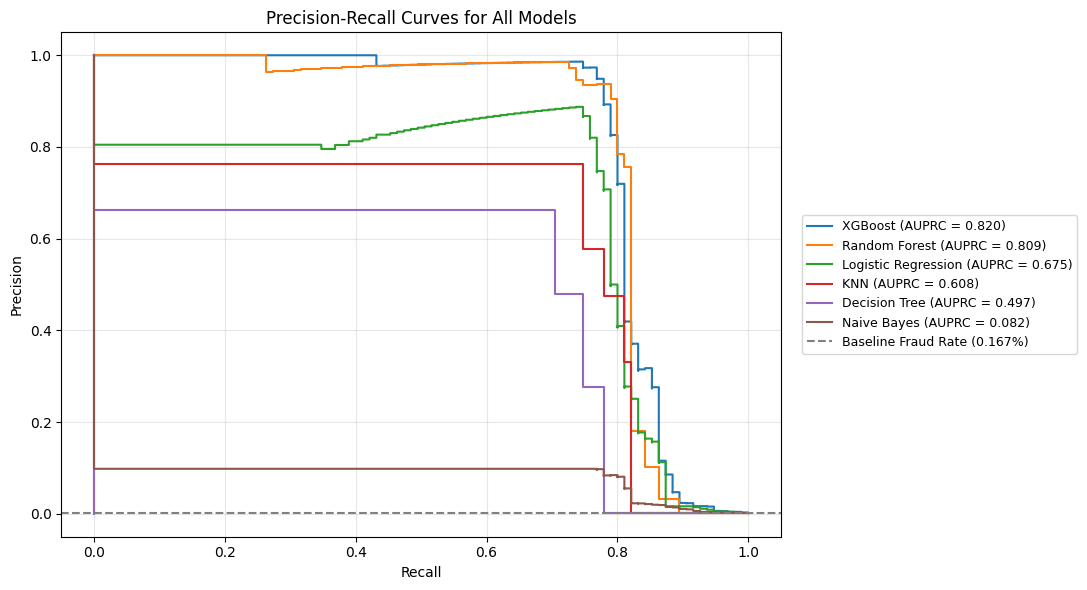

In [ ]:
# Precision-Recall curves for all models

from sklearn.metrics import precision_recall_curve

models = {"XGBoost": xgb_prob,
          "Random Forest": y_prob,
          "Logistic Regression": lr_prob,
          "KNN": knn_prob,
          "Decision Tree": dt_prob,
          "Naive Bayes": nb_prob}

plt.figure(figsize = (11, 6))

for name, prob in models.items():
    precision, recall, thresholds = precision_recall_curve(y_test, prob)
    auprc = average_precision_score(y_test, prob)
    plt.plot(recall, precision, drawstyle = "steps-post", label = f"{name} (AUPRC = {auprc:.3f})")
baseline = y_test.mean()
plt.axhline(baseline, linestyle = "--", color = "gray", label = f"Baseline Fraud Rate ({baseline:.3%})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curves for All Models")
plt.legend(loc = "center left", bbox_to_anchor = (1.02, 0.5), fontsize = 9)
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.savefig(folder + "fig_pr_all_models.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [ ]:
# Number of different probability values for each model - Rahila
for name, prob in models.items():
    print(name, "| unique probabilities:", len(np.unique(prob)), "| exactly 1.0:", (prob == 1).sum())

Random Forest | unique probabilities: 89 | exactly 1.0: 2
Logistic Regression | unique probabilities: 56053 | exactly 1.0: 41
KNN | unique probabilities: 6 | exactly 1.0: 93
Naive Bayes | unique probabilities: 55335 | exactly 1.0: 744
Decision Tree | unique probabilities: 11 | exactly 1.0: 5
XGBoost | unique probabilities: 54786 | exactly 1.0: 0


In [ ]:
# Training data for each balancing method - Rahila

from imblearn.under_sampling import RandomUnderSampler

undersample = RandomUnderSampler(sampling_strategy = 0.1, random_state = 42)
X_train_under, y_train_under = undersample.fit_resample(X_train_scaled, y_train)

print("No balancing:", y_train.value_counts().to_dict())
print("Undersampling:", y_train_under.value_counts().to_dict())
print("SMOTE:", y_train_smote.value_counts().to_dict())

No balancing: {0: 226602, 1: 378}
Undersampling: {0: 3780, 1: 378}
SMOTE: {0: 226602, 1: 22660}


In [ ]:
# Comparing balancing methods for each model

trainSets = {"No balancing": (X_train_scaled, y_train),
             "Class weight": (X_train_scaled, y_train),
             "Undersampling": (X_train_under, y_train_under),
             "SMOTE": (X_train_smote, y_train_smote)}

def make_model(name, method):
    weight = "balanced" if method == "Class weight" else None
    if name == "Logistic Regression":
        return LogisticRegression(class_weight = weight, max_iter = 1000, random_state = 42)
    if name == "Decision Tree":
        return DecisionTreeClassifier(class_weight = weight, max_depth = 10, random_state = 42)
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators = 300, class_weight = weight, random_state = 42, n_jobs = -1)
    if name == "XGBoost":
        spw = (y_train == 0).sum() / (y_train == 1).sum() if method == "Class weight" else 1
        return XGBClassifier(n_estimators = 300, max_depth = 5, learning_rate = 0.1, scale_pos_weight = spw,
                             eval_metric = "aucpr", random_state = 42, n_jobs = -1)
    if name == "KNN":
        return KNeighborsClassifier(n_neighbors = 5, n_jobs = -1)
    if name == "Naive Bayes":
        return GaussianNB()

rows = []
for name in ["Logistic Regression", "Decision Tree", "Random Forest", "XGBoost", "KNN", "Naive Bayes"]:
    for method, (X_tr, y_tr) in trainSets.items():
        if method == "Class weight" and name in ["KNN", "Naive Bayes"]:
            continue
        print("Training", name, "-", method)
        model = make_model(name, method)
        model.fit(X_tr, y_tr)
        pred = model.predict(X_test_scaled)
        prob = model.predict_proba(X_test_scaled)[:, 1]
        rows.append({"Model": name, "Balancing": method,
                     "Precision": precision_score(y_test, pred),
                     "Recall": recall_score(y_test, pred),
                     "F1": f1_score(y_test, pred),
                     "AUPRC": average_precision_score(y_test, prob)})

sampling_results = pd.DataFrame(rows)
sampling_results

Training Logistic Regression - No balancing
Training Logistic Regression - Class weight
Training Logistic Regression - Undersampling
Training Logistic Regression - SMOTE
Training Decision Tree - No balancing
Training Decision Tree - Class weight
Training Decision Tree - Undersampling
Training Decision Tree - SMOTE
Training Random Forest - No balancing
Training Random Forest - Class weight
Training Random Forest - Undersampling
Training Random Forest - SMOTE
Training XGBoost - No balancing
Training XGBoost - Class weight
Training XGBoost - Undersampling
Training XGBoost - SMOTE
Training KNN - No balancing
Training KNN - Undersampling
Training KNN - SMOTE
Training Naive Bayes - No balancing
Training Naive Bayes - Undersampling
Training Naive Bayes - SMOTE


,Model,Balancing,Precision,Recall,F1,AUPRC
0,Logistic Regression,No balancing,0.846154,0.578947,0.687500,0.691610
1,Logistic Regression,Class weight,0.055817,0.873684,0.104930,0.675156
2,Logistic Regression,Undersampling,0.303150,0.810526,0.441261,0.647012
3,Logistic Regression,SMOTE,0.434286,0.800000,0.562963,0.686837
4,Decision Tree,No balancing,0.825000,0.694737,0.754286,0.564600
5,Decision Tree,Class weight,0.227692,0.778947,0.352381,0.497137
6,Decision Tree,Undersampling,0.119380,0.810526,0.208108,0.097980
7,Decision Tree,SMOTE,0.280488,0.726316,0.404692,0.525921
8,Random Forest,No balancing,0.972222,0.736842,0.838323,0.797830
9,Random Forest,Class weight,0.985507,0.715789,0.829268,0.808408


In [ ]:
# AUPRC for each model and balancing method
sampling_results.pivot(index = "Model", columns = "Balancing", values = "AUPRC").round(3)

Balancing,Class weight,No balancing,SMOTE,Undersampling
Model,,,,
Decision Tree,0.497,0.565,0.526,0.098
KNN,NaN,0.769,0.608,0.493
Logistic Regression,0.675,0.692,0.687,0.647
Naive Bayes,NaN,0.076,0.082,0.076
Random Forest,0.808,0.798,0.818,0.681
XGBoost,0.817,0.829,0.816,0.715


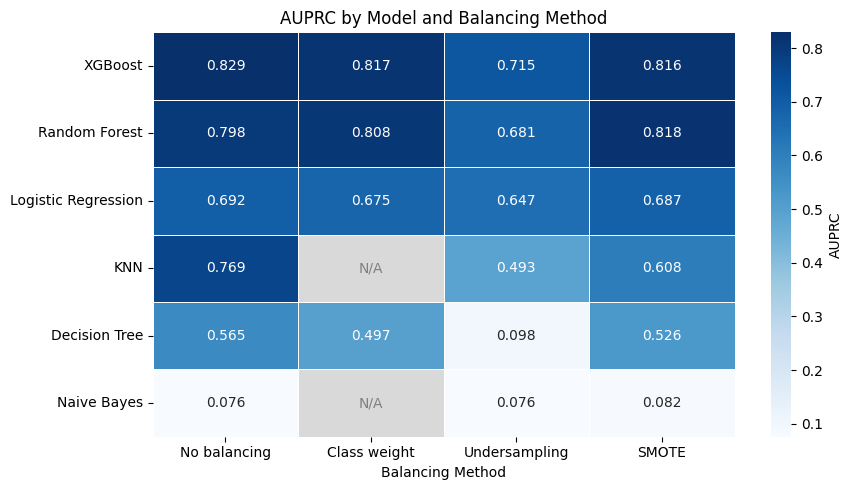

In [ ]:
# AUPRC by model and balancing method heatmap - Rahila
auprcTable = sampling_results.pivot(index = "Model", columns = "Balancing", values = "AUPRC")
auprcTable = auprcTable[["No balancing", "Class weight", "Undersampling", "SMOTE"]]
auprcTable = auprcTable.loc[["XGBoost", "Random Forest", "Logistic Regression", "KNN", "Decision Tree", "Naive Bayes"]]

plt.figure(figsize = (9, 5))
ax = sns.heatmap(auprcTable, annot = True, fmt = ".3f", cmap = "Blues", linewidths = 0.5, cbar_kws = {"label": "AUPRC"})
ax.set_facecolor("#d9d9d9")

for i in range(auprcTable.shape[0]):
    for j in range(auprcTable.shape[1]):
        if pd.isna(auprcTable.iloc[i, j]):
            ax.text(j + 0.5, i + 0.5, "N/A", ha = "center", va = "center", color = "gray")

plt.title("AUPRC by Model and Balancing Method")
plt.xlabel("Balancing Method")
plt.ylabel("")
plt.tight_layout()
plt.savefig(folder + "fig_sampling_auprc.png", dpi = 300, bbox_inches = "tight")
plt.show()

In [ ]:

import pandas as pd
import numpy as np

ieee_clean = pd.read_parquet("/content/ieee_clean.parquet")

print("Dataset shape:", ieee_clean.shape)
print("\nFraud distribution:")
print(ieee_clean["isFraud"].value_counts())
print("\nFraud percentages:")
print(ieee_clean["isFraud"].value_counts(normalize=True) * 100)
print("\nDuplicate TransactionIDs:",
      ieee_clean["TransactionID"].duplicated().sum()
      if "TransactionID" in ieee_clean.columns else "ID not present")


Dataset shape: (590540, 423)

Fraud distribution:
isFraud
0    569877
1     20663
Name: count, dtype: int64

Fraud percentages:
isFraud
0    96.500999
1     3.499001
Name: proportion, dtype: float64

Duplicate TransactionIDs: 0


In [ ]:

import pandas as pd
import numpy as np
import gc

df = pd.read_parquet("/content/ieee_clean.parquet")

print("Original shape:", df.shape)

# Keep numeric predictors
df = df.select_dtypes(include=np.number).copy()

# Reduce memory usage
for col in df.select_dtypes(include=["float64"]).columns:
    df[col] = df[col].astype("float32")

print("Memory usage:",
      round(df.memory_usage(deep=True).sum() / 1024**2, 2),
      "MB")

print("Fraud rate:", df["isFraud"].mean())


Original shape: (590540, 423)
Memory usage: 898.84 MB
Fraud rate: 0.03499000914417313


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

y = df["isFraud"].to_numpy(dtype=np.int8)

X = df.drop(
    columns=["isFraud", "TransactionID"],
    errors="ignore"
)

X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna(axis=1, how="all")

X = X.to_numpy(dtype=np.float32)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

del X, df
gc.collect()

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train).astype("float32")
X_test = imputer.transform(X_test).astype("float32")

gc.collect()

print("Training:", X_train.shape)
print("Testing:", X_test.shape)


Training: (472432, 392)
Testing: (118108, 392)


In [ ]:

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    precision_score, recall_score,
    f1_score, average_precision_score,
    precision_recall_curve
)
import matplotlib.pyplot as plt

results = []
curves = {}

fraud_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=500, class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=15,
        class_weight="balanced",
        random_state=42, n_jobs=2
    ),
    "Naive Bayes": GaussianNB(),
    "XGBoost": XGBClassifier(
        n_estimators=150, max_depth=5,
        learning_rate=0.1,
        scale_pos_weight=fraud_weight,
        tree_method="hist",
        eval_metric="aucpr",
        random_state=42, n_jobs=2
    )
}

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train).astype("float32")
X_test_scaled = scaler.transform(X_test).astype("float32")

for name, model in models.items():
    print("Training:", name, flush=True)

    if name in ["Logistic Regression", "Naive Bayes"]:
        train_data, test_data = X_train_scaled, X_test_scaled
    else:
        train_data, test_data = X_train, X_test

    model.fit(train_data, y_train)

    pred = model.predict(test_data)
    prob = model.predict_proba(test_data)[:, 1]

    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "AUPRC": average_precision_score(y_test, prob)
    })

    curves[name] = precision_recall_curve(y_test, prob)[:2]

    del model, pred, prob
    gc.collect()

results_ieee = pd.DataFrame(results)
display(results_ieee.sort_values("AUPRC", ascending=False).round(4))


Training: Logistic Regression
Training: Decision Tree
Training: Random Forest
Training: Naive Bayes
Training: XGBoost


,Model,Precision,Recall,F1,AUPRC
4,XGBoost,0.2034,0.7910,0.3236,0.6027
2,Random Forest,0.2625,0.7026,0.3823,0.5697
0,Logistic Regression,0.1380,0.7164,0.2315,0.4215
1,Decision Tree,0.1609,0.7539,0.2652,0.4148
3,Naive Bayes,0.0525,0.8776,0.0990,0.0767


In [ ]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

sample_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=min(20000, len(y_train) - 1),
    stratify=y_train,
    random_state=42
)

knn = KNeighborsClassifier(
    n_neighbors=5,
    n_jobs=2
)

knn.fit(X_train_scaled[sample_indices], y_train[sample_indices])

knn_pred = knn.predict(X_test_scaled)
knn_prob = knn.predict_proba(X_test_scaled)[:, 1]

results_ieee = pd.concat([
    results_ieee,
    pd.DataFrame([{
        "Model": "KNN",
        "Precision": precision_score(y_test, knn_pred, zero_division=0),
        "Recall": recall_score(y_test, knn_pred, zero_division=0),
        "F1": f1_score(y_test, knn_pred, zero_division=0),
        "AUPRC": average_precision_score(y_test, knn_prob)
    }])
], ignore_index=True)

curves["KNN"] = precision_recall_curve(y_test, knn_prob)[:2]

display(results_ieee.sort_values("AUPRC", ascending=False).round(4))


,Model,Precision,Recall,F1,AUPRC
4,XGBoost,0.2034,0.7910,0.3236,0.6027
2,Random Forest,0.2625,0.7026,0.3823,0.5697
0,Logistic Regression,0.1380,0.7164,0.2315,0.4215
1,Decision Tree,0.1609,0.7539,0.2652,0.4148
5,KNN,0.7600,0.1878,0.3011,0.2617
3,Naive Bayes,0.0525,0.8776,0.0990,0.0767


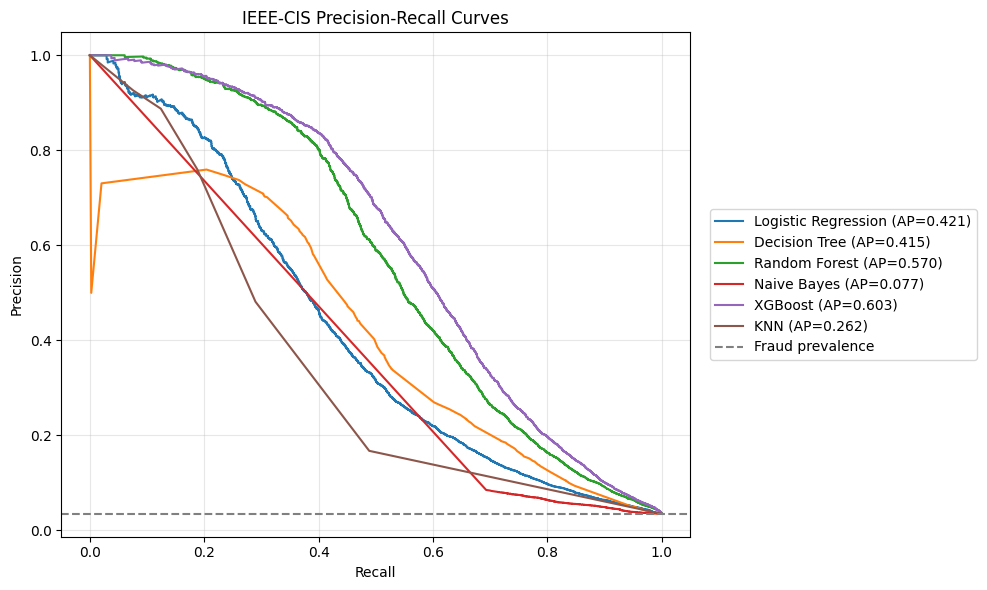

In [ ]:

plt.figure(figsize=(10, 6))

for name, (precision, recall) in curves.items():
    ap = results_ieee.loc[
        results_ieee["Model"] == name, "AUPRC"
    ].iloc[0]

    plt.plot(recall, precision,
             label=f"{name} (AP={ap:.3f})")

plt.axhline(y_test.mean(), linestyle="--",
            color="gray", label="Fraud prevalence")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("IEEE-CIS Precision-Recall Curves")
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ieee_precision_recall.png",
            dpi=300, bbox_inches="tight")
plt.show()


In [ ]:

import pandas as pd

# Display results for all six models
model_comparison = results_ieee.copy()

# Sort by AUPRC (highest to lowest)
model_comparison = model_comparison.sort_values(
    by="AUPRC", ascending=False
).reset_index(drop=True)

# Round to 4 decimal places
model_comparison = model_comparison.round(4)

print("IEEE-CIS Model Performance Comparison")
display(model_comparison)


IEEE-CIS Model Performance Comparison


,Model,Precision,Recall,F1,AUPRC
0,XGBoost,0.2034,0.7910,0.3236,0.6027
1,Random Forest,0.2625,0.7026,0.3823,0.5697
2,Logistic Regression,0.1380,0.7164,0.2315,0.4215
3,Decision Tree,0.1609,0.7539,0.2652,0.4148
4,KNN,0.7600,0.1878,0.3011,0.2617
5,Naive Bayes,0.0525,0.8776,0.0990,0.0767


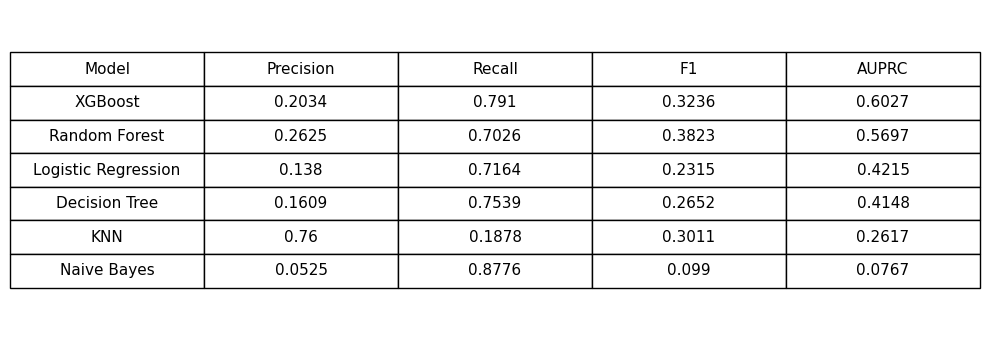

In [ ]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.axis("off")

table = ax.table(
    cellText=model_comparison.values,
    colLabels=model_comparison.columns,
    cellLoc="center",
    loc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1, 1.7)

plt.tight_layout()
plt.savefig(
    "ieee_model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [ ]:
# Validation split for choosing the threshold
X_tr, X_val, y_tr, y_val = train_test_split(X_train, y_train, test_size = 0.20, stratify = y_train, random_state = 42)

rf_thresh = RandomForestClassifier(n_estimators = 300, class_weight = "balanced", random_state = 42, n_jobs = -1)
rf_thresh.fit(X_tr, y_tr)

val_prob = rf_thresh.predict_proba(X_val)[:, 1]
test_prob = rf_thresh.predict_proba(X_test)[:, 1]

print("Validation fraud cases:", y_val.sum())

Validation fraud cases: 76


Best threshold: 0.427


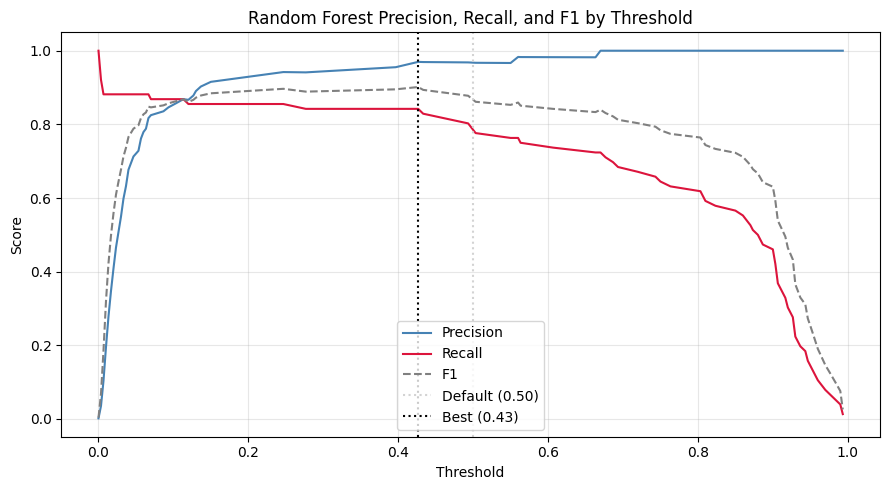

In [ ]:
# Precision, recall, and F1 at each threshold
from sklearn.metrics import precision_recall_curve, confusion_matrix

precision, recall, thresholds = precision_recall_curve(y_val, val_prob)
f1 = 2 * precision * recall / (precision + recall + 1e-10)
bestIndex = np.argmax(f1[:-1])
bestThreshold = thresholds[bestIndex]
print("Best threshold:", round(bestThreshold, 3))

plt.figure(figsize = (9, 5))
plt.plot(thresholds, precision[:-1], label = "Precision", color = "steelblue")
plt.plot(thresholds, recall[:-1], label = "Recall", color = "crimson")
plt.plot(thresholds, f1[:-1], label = "F1", color = "gray", linestyle = "--")
plt.axvline(0.5, color = "lightgray", linestyle = ":", label = "Default (0.50)")
plt.axvline(bestThreshold, color = "black", linestyle = ":", label = f"Best ({bestThreshold:.2f})")
plt.title("Random Forest Precision, Recall, and F1 by Threshold")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid(alpha = 0.3)
plt.tight_layout()
plt.savefig(folder + "fig_rf_threshold_curve.png", dpi = 300, bbox_inches = "tight")
plt.show()

        Threshold  Fraud caught  Missed fraud  False alarms  Precision  \
0  Default (0.50)            67            28             1      0.985   
1     Best (0.43)            68            27             3      0.958   

   Recall     F1  
0   0.705  0.822  
1   0.716  0.819  


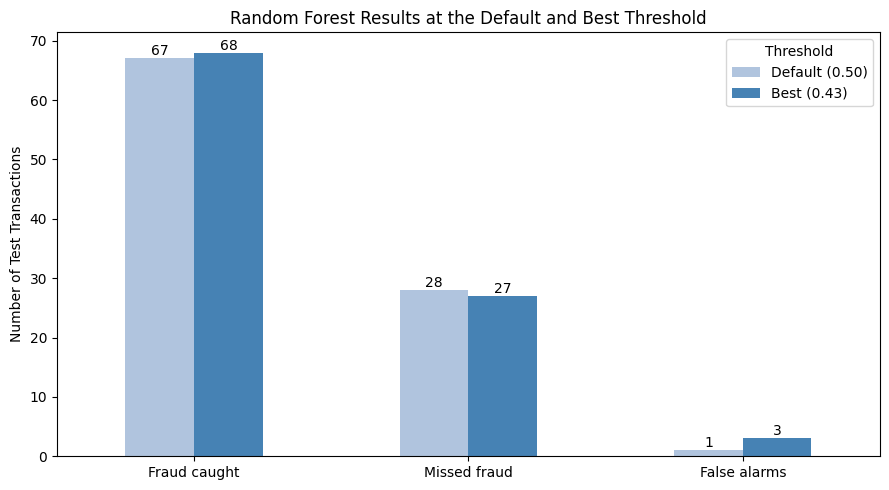

In [ ]:
# False alarms and missed fraud at the default and best threshold
rows = []
for name, t in [("Default (0.50)", 0.5), (f"Best ({bestThreshold:.2f})", bestThreshold)]:
    pred = (test_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    rows.append({"Threshold": name, "Fraud caught": tp, "Missed fraud": fn, "False alarms": fp,
                 "Precision": precision_score(y_test, pred), "Recall": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

thresholdResults = pd.DataFrame(rows)
print(thresholdResults.round(3))

plotData = thresholdResults.set_index("Threshold")[["Fraud caught", "Missed fraud", "False alarms"]].T
ax = plotData.plot(kind = "bar", figsize = (9, 5), color = ["lightsteelblue", "steelblue"], rot = 0)
for bars in ax.containers:
    ax.bar_label(bars)
plt.title("Random Forest Results at the Default and Best Threshold")
plt.ylabel("Number of Test Transactions")
plt.xlabel("")
plt.legend(title = "Threshold")
plt.tight_layout()
plt.savefig(folder + "fig_rf_threshold_bar.png", dpi = 300, bbox_inches = "tight")
plt.show()